In [1]:
# Checking 
print("Hello World")

Hello World


In [2]:
#1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings("ignore")

#1.1. Setting Chart Style
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

In [3]:
#2. Dataset Upload and Read CSV
df=pd.read_csv("100 Sales.csv")
print(f"\n Dataset First 5 lines:")
print(df.head())
print(f"\n Dataset Last 5 lines:")
print(df.tail())


 Dataset First 5 lines:
   ID_Venda  Data_Venda         Vendedor    Regiao   Produto    Categoria  \
0       101  15/01/2025        ana.souza       SUL  Notebook  Eletrônicos   
1       102  15/01/2025  carlos.oliveira   SUDESTE     Mouse  Eletrônicos   
2       103  16/01/2025        ana.souza       SUL   Teclado  Eletrônicos   
3       104  16/01/2025    mariana.costa  NORDESTE   Cadeira       Móveis   
4       105  17/01/2025  carlos.oliveira   SUDESTE      Mesa       Móveis   

   Quantidade  Preco_Unitario  Total_Venda    Status  
0           2            3500         7000  Entregue  
1           5              80          400  Entregue  
2           3             200          600  Entregue  
3           1             750          750  Pendente  
4           2            1200         2400  Entregue  

 Dataset Last 5 lines:
    ID_Venda  Data_Venda         Vendedor    Regiao   Produto    Categoria  \
95       196  03/03/2025    mariana.costa  NORDESTE      Mesa       Móveis   
96

In [22]:
#3. EXPLORATORY DATA ANALYSIS
print("="*50)
print("INITIAL EXPLORATORY DATA ANALYSIS")
print("="*50)

#3.1. DATASET OVERVIEW
print(f"\n Dataframe Dimensions:{df.shape}")
print(f"\n Dataset Info:")
print(df.info())

#3.2. Descriptive Statistics
print(f"\n Descriptive Statistics (Numeric Variables):")
print(df.describe())

#3.3. LOOKING FOR NULL VALUES
print(f"\n Null Values by Columns:\n {df.isnull().sum()}")

#3.4 LOOKING FOR UNIQUE VALUES BY CATEGORY (strings)
print("\n Unique Values by Column:")
categories=["Vendedor", "Regiao", "Produto", "Categoria", "Status"]
for col in categories:
    print(f"\n{col}:{df[col].unique()}")
    print(f"Quantidade: {df[col].nunique()}")



INITIAL EXPLORATORY DATA ANALYSIS

 Dataframe Dimensions:(100, 15)

 Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   ID_Venda         100 non-null    int64         
 1   Data_Venda       100 non-null    datetime64[us]
 2   Vendedor         100 non-null    str           
 3   Regiao           100 non-null    str           
 4   Produto          100 non-null    str           
 5   Categoria        100 non-null    str           
 6   Quantidade       100 non-null    int64         
 7   Preco_Unitario   100 non-null    int64         
 8   Total_Venda      100 non-null    int64         
 9   Status           100 non-null    str           
 10  Total_Calculado  100 non-null    int64         
 11  Diference        100 non-null    int64         
 12  Month            100 non-null    int32         
 13  Weekday          100 non

In [5]:
#4. DATA CLEANING AND PROCESSING
print("="*50)
print("DATA CLEANING AND PROCESSING")
print("="*50)

#4.1. Solving Inconsistency in the Column Região (SUL vs Sul)
df["Regiao"]=df["Regiao"].str.upper()
print(f"\n Standardized Regions: {df["Regiao"].unique}")

#4.2. Convert Data_Venda to Datetime
df["Data_Venda"]=pd.to_datetime(df["Data_Venda"],format="%d/%m/%Y")
print(f"\n Data_Venda Convertida para datetime")

#4.3. Checking Duplicates
duplicates=df.duplicated().sum()
print(f"\n Records of Duplicates:{duplicates}")

#4.4. Checking if Total_Vendas = Quantidade x Preco_Unitario
df["Total_Calculado"]=df["Quantidade"]*df["Preco_Unitario"]
df["Diference"]=df["Total_Venda"]-df["Total_Calculado"]
Inconsistencies=df[df["Diference"]!=0]
print(f"\n Inconsistencies in the Total: {len(Inconsistencies)}")

#4.5. Create Columns for Month and Weekday
df["Month"]=df["Data_Venda"].dt.month
df["Weekday"]=df["Data_Venda"].dt.day_name()
df["Day"]=df["Data_Venda"].dt.day

#4.6. Standardize Status
df["Status"]=df["Status"].str.capitalize()

DATA CLEANING AND PROCESSING

 Standardized Regions: <bound method Series.unique of 0          SUL
1      SUDESTE
2          SUL
3     NORDESTE
4      SUDESTE
        ...   
95    NORDESTE
96         SUL
97     SUDESTE
98       NORTE
99    NORDESTE
Name: Regiao, Length: 100, dtype: str>

 Data_Venda Convertida para datetime

 Records of Duplicates:0

 Inconsistencies in the Total: 0


In [6]:
#5. STATISTICS AND BUSINESS ANALYSIS
print("="*50)
print("BUSINESS ANALYSIS")
print("="*50)

#5.1. SALES BY STATUS
print("\n Sales by Status:")
status_counts=df["Status"].value_counts()
print(f"\n Delivery Percentage:{status_counts.get("Entregue",0)/len(df)*100:.1f}%")

#5.2. Top sellers by Revenue
print("\n Top 5 Sellers by Revenue:")
top_sellers=df.groupby("Vendedor")["Total_Venda"].sum().sort_values(ascending=False)
print(top_sellers.head())

#5.3. Revenue by Region
print("\n Revenue by Region:")
revenue_region=df.groupby("Regiao")["Total_Venda"].sum().sort_values(ascending=False)
print(revenue_region)

#5.4. Sales by Category
print("\n Sales by Category:")
sales_category=df.groupby("Categoria")["Total_Venda"].sum().sort_values(ascending=False)
print(sales_category)

#5.5. Best Seller Products (Quantity)
print("\n Top 5 Best Seller Products(Quantity):")
top_products_qty=df.groupby("Produto")["Quantidade"].sum().sort_values(ascending=False).head()
print(top_products_qty) 

#5.6. Products with Best Revenue
print("\n Products with Best Revenue:")
top_products_rev=df.groupby("Produto")["Total_Venda"].sum().sort_values(ascending=False).head()
print(top_products_rev)

#5.7. Pendency and Canceling Analysis
print("\n Problems Analysis:")
problems=df[df["Status"]!="Entregue"]
print(f"\n Total of Problems:{len(problems)}({len(problems)/len(df)*100:.1f}%)")
print("\n Problems by Seller:")
print(problems.groupby("Vendedor").size())
print("\n Problems by Region:")
print(problems.groupby("Regiao").size()) 

#5.8. Mean of Price by Category
print("\n Mean of Price by Category:")
mean_price_cat=df.groupby("Categoria")["Preco_Unitario"].mean().sort_values(ascending=False)
print(mean_price_cat)

BUSINESS ANALYSIS

 Sales by Status:

 Delivery Percentage:80.0%

 Top 5 Sellers by Revenue:
Vendedor
carlos.oliveira    47506
pedro.lima         34224
mariana.costa      32080
ana.souza          29394
Name: Total_Venda, dtype: int64

 Revenue by Region:
Regiao
SUDESTE     47506
NORTE       34224
NORDESTE    32080
SUL         29394
Name: Total_Venda, dtype: int64

 Sales by Category:
Categoria
Eletrônicos    102910
Móveis          36450
Papelaria        3844
Name: Total_Venda, dtype: int64

 Top 5 Best Seller Products(Quantity):
Produto
Caneta     790
Caderno    283
Fone        93
Mouse       52
Teclado     26
Name: Quantidade, dtype: int64

 Products with Best Revenue:
Produto
Notebook    70000
Mesa        19200
Monitor     18900
Cadeira     17250
Teclado      5200
Name: Total_Venda, dtype: int64



 Problems Analysis:

 Total of Problems:20(20.0%)

 Problems by Seller:
Vendedor
ana.souza          7
carlos.oliveira    2
mariana.costa      4
pedro.lima         7
dtype: int64

 Problems by Region:
Regiao
NORDESTE    4
NORTE       7
SUDESTE     2
SUL         7
dtype: int64

 Mean of Price by Category:
Categoria
Eletrônicos    991.607143
Móveis         975.000000
Papelaria        5.000000
Name: Preco_Unitario, dtype: float64


GENERATING VISUALS


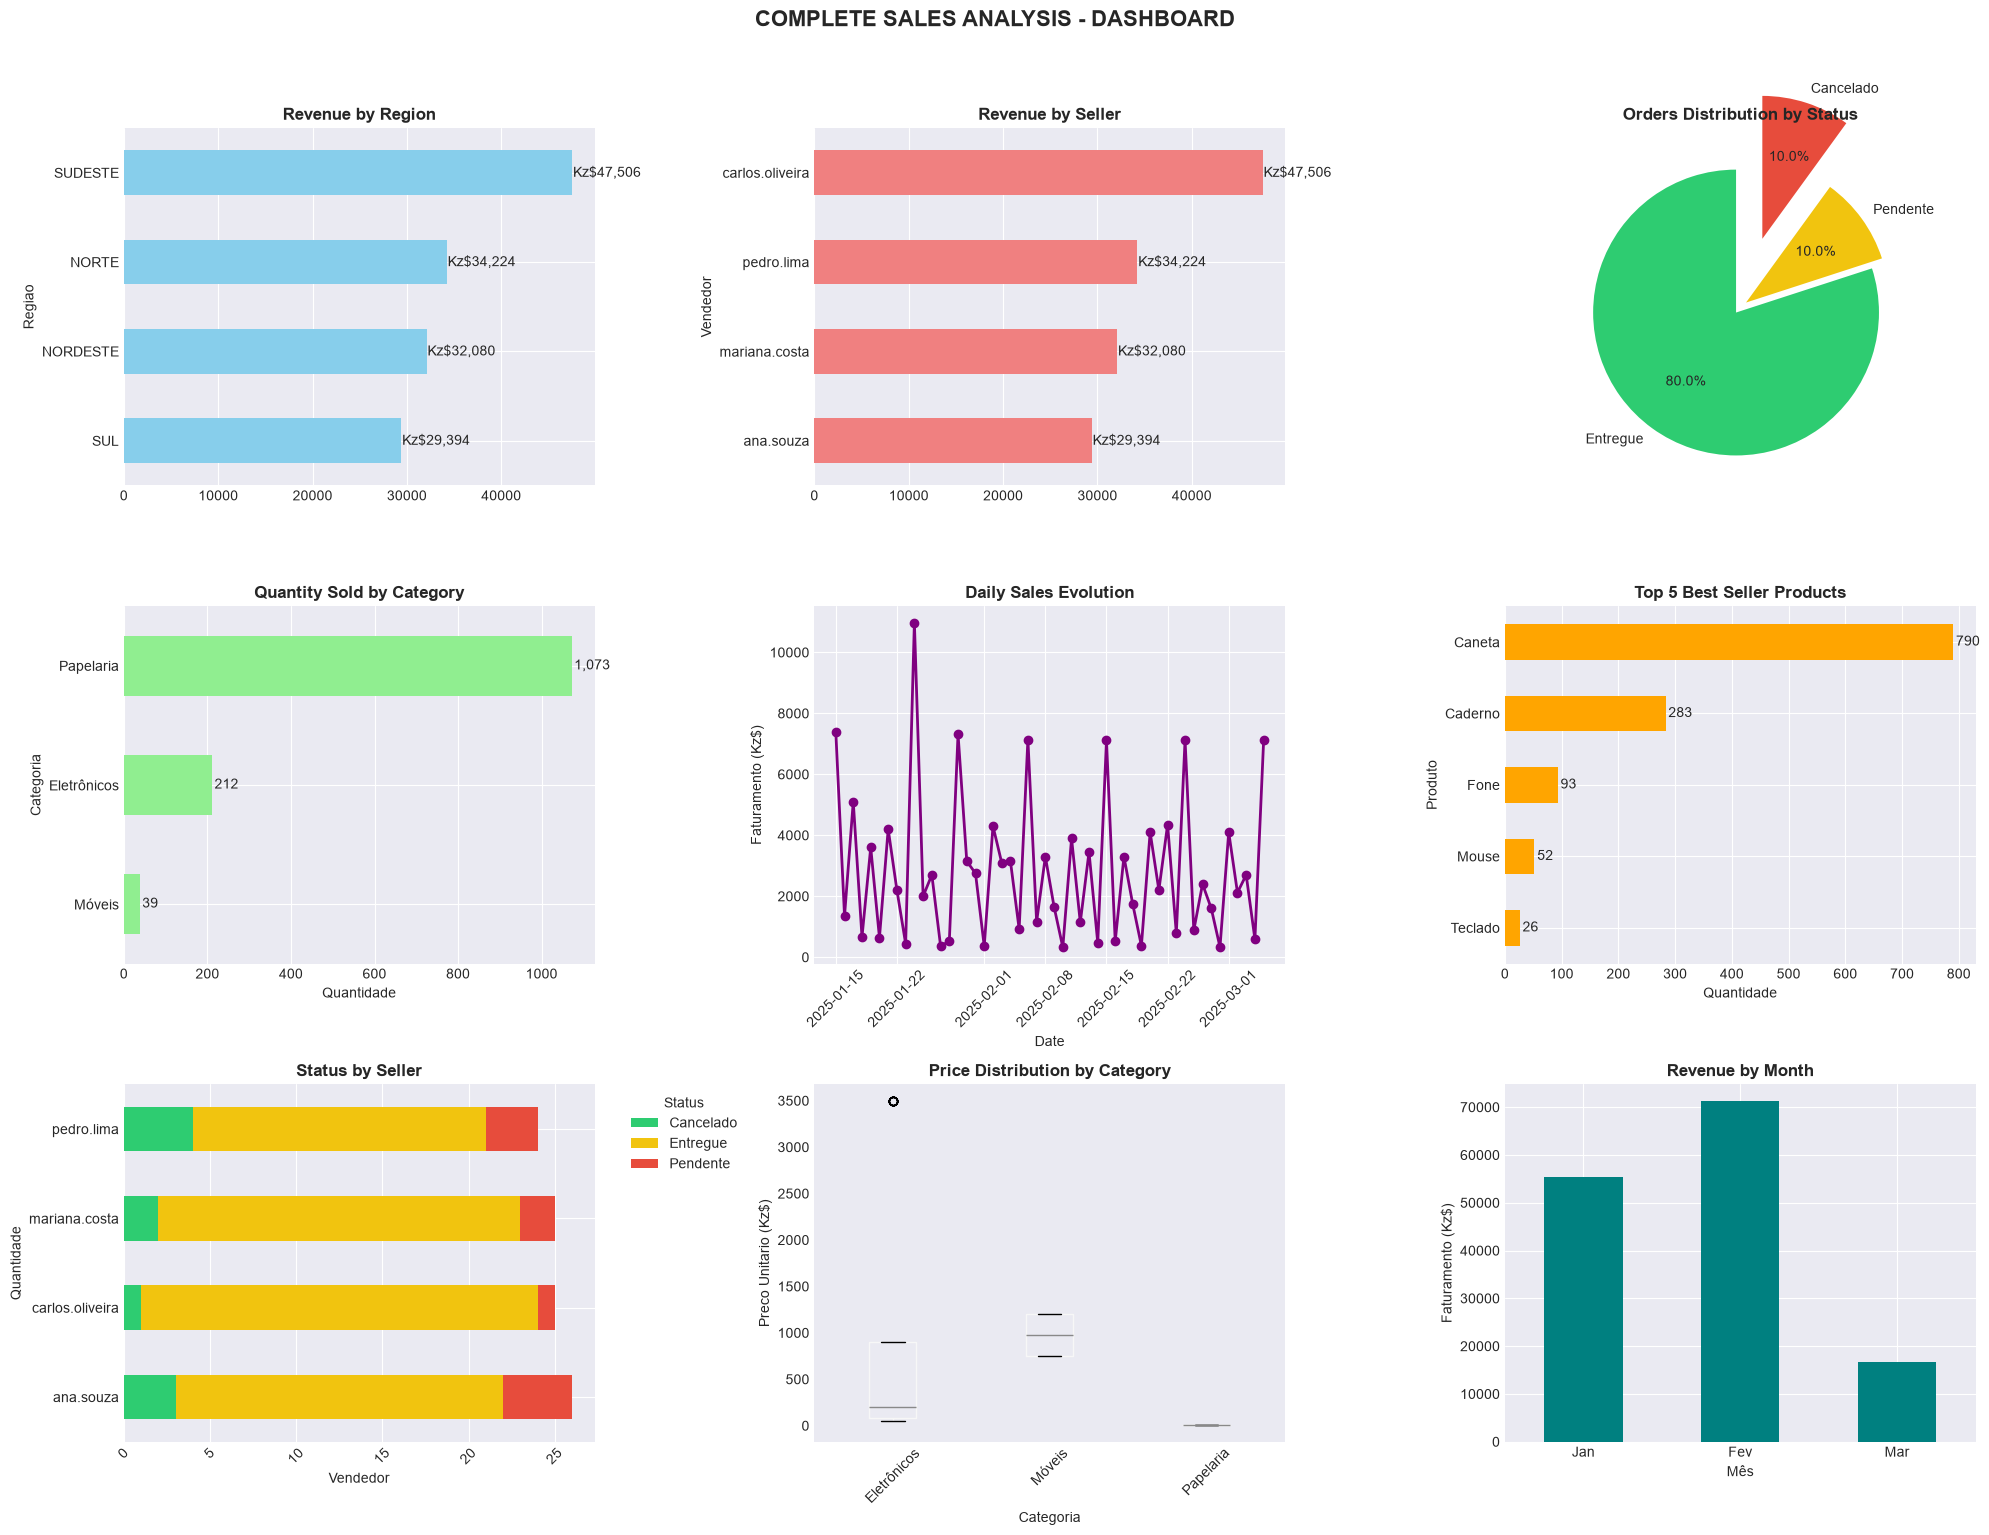

In [21]:
#6. VISUALIZATIONS
print("="*50)
print("GENERATING VISUALS")
print("="*50)

# Set Up the Figure
fig=plt.figure(figsize=(20, 15))

#6.1. Revenue by Region (Bar)
ax1=plt.subplot(3,3,1)
df.groupby("Regiao")["Total_Venda"].sum().sort_values().plot(kind="barh", ax=ax1, color="skyblue")
ax1.set_title("Revenue by Region", fontsize=12, fontweight="bold")
ax1.set_label("Revenue(Kz$)")
for i, v in enumerate(df.groupby("Regiao")["Total_Venda"].sum().sort_values()):
    ax1.text(v+100, i, f"Kz${v:,.0f}", va="center")

#6.2. Revenue by Seller (Bar)
ax2=plt.subplot(3,3,2)
df.groupby("Vendedor")["Total_Venda"].sum().sort_values().plot(kind="barh", ax=ax2, color="lightcoral")
ax2.set_title("Revenue by Seller", fontsize=12, fontweight="bold")
ax2.set_label("Revenue(Kz$)")
for i, v in enumerate(df.groupby("Vendedor")["Total_Venda"].sum().sort_values()):
    ax2.text(v+100, i, f"Kz${v:,.0f}", va="center")

#6.3. Status Distribution (Pizza)
ax3=plt.subplot(3,3,3)
status_counts=df["Status"].value_counts()
colors=["#2ecc71", "#f1c40f", "#e74c3c"]
ax3.pie(status_counts,labels=status_counts.index,autopct="%1.1f%%", colors=colors, startangle=90,explode=(0.05,0.05,0.5))
ax3.set_title("Orders Distribution by Status",fontsize=12,fontweight="bold")

#6.4. Quantity sold by Category (Bar)
ax4=plt.subplot(3,3,4)
df.groupby("Categoria")["Quantidade"].sum().sort_values().plot(kind="barh",ax=ax4,color="lightgreen")
ax4.set_title("Quantity Sold by Category", fontsize=12,fontweight="bold")
ax4.set_xlabel("Quantidade")
for i, v in enumerate(df.groupby("Categoria")["Quantidade"].sum().sort_values()):
    ax4.text(v+5, i, f"{v:,.0f}", va="center" )

#6.5. Daily Sales (line)
ax5=plt.subplot(3,3,5)
daily_sales=df.groupby("Data_Venda")["Total_Venda"].sum()
ax5.plot(daily_sales.index, daily_sales.values, marker="o", linewidth=2, color="purple")
ax5.set_title("Daily Sales Evolution", fontsize=12, fontweight="bold")
ax5.set_xlabel("Date")
ax5.set_ylabel("Faturamento (Kz$)")
ax5.tick_params(axis="x", rotation=45)

#6.6. Top 5 Product best sellers (Top5)
ax6=plt.subplot(3,3,6)
top5=df.groupby("Produto")["Quantidade"].sum().sort_values(ascending=True).tail(5)
top5.plot(kind="barh",ax=ax6,color="orange")
ax6.set_title("Top 5 Best Seller Products", fontsize=12,fontweight="bold")
ax6.set_xlabel("Quantidade")
for i, v in enumerate(top5):
    ax6.text(v+5, i, f"{v:,.0f}", va="center" )

#6.7 Status by Seller (Stacked)
ax7=plt.subplot(3,3,7)
status_seller=pd.crosstab(df["Vendedor"], df["Status"])
status_seller.plot(kind="barh", stacked=True,ax=ax7,
color=["#2ecc71", "#f1c40f", "#e74c3c"])
ax7.set_title("Status by Seller",fontsize=12,fontweight="bold")
ax7.set_xlabel("Vendedor")
ax7.set_ylabel("Quantidade")
ax7.legend(title="Status",bbox_to_anchor=(1.05,1))
ax7.tick_params(axis="x",rotation=45)

#6.8. Price Distribution by Category (Boxplot)
ax8=plt.subplot(3,3,8)
df.boxplot(column="Preco_Unitario",by="Categoria",ax=ax8,grid=False)
ax8.set_title("Price Distribution by Category",fontsize=12,fontweight="bold")
ax8.set_xlabel("Categoria")
ax8.set_ylabel("Preco Unitario (Kz$)")
ax8.tick_params(axis="x", rotation=45)

#6.9. Revenue by Month (Bar)
ax9=plt.subplot(3,3,9)
df.groupby("Month")["Total_Venda"].sum().plot(kind="bar",ax=ax9,color="teal")
ax9.set_title("Revenue by Month",fontsize=12,fontweight="bold")
ax9.set_xlabel("Mês")
ax9.set_ylabel("Faturamento (Kz$)")
ax9.set_xticklabels(["Jan","Fev","Mar"], rotation=0)
plt.tight_layout()
plt.suptitle("COMPLETE SALES ANALYSIS - DASHBOARD", fontsize=16,fontweight="bold", y=1.02);